# Лаб_2. Рекомендация друзей на социальном графе Last.fm

**Автор:** Алексеев Георгий Александрович M3412

Строим рекомендательную систему на графе дружеских связей: по текущему списку друзей пользователя предсказываем новых (задача `People You May Know`). Основной сигнал - общие друзья: при большом числе общих друзей вероятность связи между двумя пользователями высока.

Объект рекомендации - пользователь. Для каждого пользователя формируется ранжированный список из K = 10 кандидатов, которые ещё не являются его друзьями. Целевая переменная - наличие дружеской связи между парой пользователей (бинарная).

План: описание датасета (п. 1) -> EDA и предобработка (п. 2) -> разбиение на обучение, валидацию и тест (п. 3) -> четыре метода из разных семейств (п. 4) -> метрики и подбор гиперпараметров (п. 5) -> сравнение на тесте и устойчивость результатов (п. 6) -> предложения по улучшению и выводы (п. 7).

## 0. Подготовка окружения

`scipy.sparse` - матрицы смежности, `networkx` - описательная статистика графа (компоненты, кластеризация, k-ядро), `sklearn.preprocessing.normalize` - нормировка строк для косинусного сходства.

In [23]:
import os, glob, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
from scipy.sparse.linalg import svds
from sklearn.preprocessing import normalize
import networkx as nx

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
RND = 42
K = 10
DATA = "data/lastfm2k"

## 1. Датасет

HetRec-2011 Last.fm (GroupLens). Датасет содержит данные 1892 пользователей сервиса Last.fm: прослушивания исполнителей, теги и социальный граф. Состав файлов:

In [24]:
desc = []
for f in sorted(glob.glob(f"{DATA}/*.dat")):
    df = pd.read_csv(f, sep="\t", encoding="latin-1")
    desc.append({"файл": os.path.basename(f), "строк": len(df), "колонки": ", ".join(df.columns)})
pd.DataFrame(desc)

,файл,строк,колонки
0,artists.dat,17632,"id, name, url, pictureURL"
1,tags.dat,11946,"tagID, tagValue"
2,user_artists.dat,92834,"userID, artistID, weight"
3,user_friends.dat,25434,"userID, friendID"
4,user_taggedartists-timestamps.dat,186479,"userID, artistID, tagID, timestamp"
5,user_taggedartists.dat,186479,"userID, artistID, tagID, day, month, year"


Для задачи используется `user_friends.dat` - список дружеских связей. Остальные файлы описывают взаимодействие пользователей с контентом (исполнители, теги) и в базовой постановке не участвуют; их возможное применение рассматривается в п. 7.

Каждая строка `user_friends.dat` - направленная пара `(userID, friendID)`. Дружба взаимная, поэтому каждая связь записана дважды: `(u, v)` и `(v, u)`.

In [25]:
uf = pd.read_csv(f"{DATA}/user_friends.dat", sep="\t")
print("строк (направленных пар):", len(uf))
uf.head()

строк (направленных пар): 25434


,userID,friendID
0,2,275
1,2,428
2,2,515
3,2,761
4,2,831


## 2. Разведочный анализ данных (EDA)

### 2.1. Размер и плотность графа

Плотность - доля реализованных связей среди всех возможных пар пользователей: `2|E| / (n(n - 1))`.

In [26]:
n_users = pd.unique(uf[["userID", "friendID"]].values.ravel()).size
n_edges = len(uf) // 2
density = 2 * n_edges / (n_users * (n_users - 1))
print(f"пользователей: {n_users}")
print(f"дружб (неориентированных рёбер): {n_edges}")
print(f"средняя степень: {2 * n_edges / n_users:.1f}")
print(f"плотность: {density:.4f} ({density * 100:.2f}%)")

пользователей: 1892
дружб (неориентированных рёбер): 12717
средняя степень: 13.4
плотность: 0.0071 (0.71%)


**Вывод.** Граф разреженный: реализовано 0.71% возможных пар, в среднем 13.4 друга на пользователя. Матрица смежности `1892 x 1892` содержит менее 1% ненулевых элементов, поэтому дальше используется разреженное представление `scipy.sparse`.

### 2.2. Качество данных

Для списка рёбер проверяем пропуски, дубликаты строк, петли (`userID = friendID`) и симметричность (каждая ли связь записана в обе стороны). Выбросами в невзвешенном графе могут быть только узлы с аномально большой степенью; границу определяем по правилу 1.5*IQR: степень больше `Q3 + 1.5*(Q3 - Q1)`.

In [27]:
pairs = set(map(tuple, uf[["userID", "friendID"]].values))
deg_full = uf.groupby("userID").size()
q1, q3 = deg_full.quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
quality = {
    "пропуски (NaN)": int(uf.isna().sum().sum()),
    "дубликаты строк": int(uf.duplicated().sum()),
    "петли": int((uf.userID == uf.friendID).sum()),
    "несимметричные пары": sum(1 for a, b in pairs if (b, a) not in pairs),
    "граница выбросов по степени (1.5*IQR)": round(fence, 1),
    "пользователей выше границы": f"{(deg_full > fence).sum()} ({(deg_full > fence).mean():.1%})",
    "связей у них (доля всех)": f"{deg_full[deg_full > fence].sum() / len(uf):.1%}",
}
pd.Series(quality, name="значение").to_frame()

,значение
пропуски (NaN),0
дубликаты строк,0
петли,0
несимметричные пары,0
граница выбросов по степени (1.5*IQR),38.0
пользователей выше границы,173 (9.1%)
связей у них (доля всех),39.9%


**Вывод.** Пропусков, дубликатов и петель нет, все связи записаны в обе стороны - граф неориентированный и очистки не требует.

По правилу 1.5*IQR выбросами по степени являются 173 пользователя (9.1%) с числом друзей больше 38; на них приходится 39.9% всех связей. Эти узлы не удаляем: это не ошибки записи, а пользователи с большим числом друзей, и их удаление убрало бы 40% связей и исказило бы структуру графа. Влияние таких узлов на выдачу измеряется метрикой Novelty (п. 5).

### 2.3. Распределение степеней и структура графа

Степень узла - число друзей пользователя. Коэффициент кластеризации узла - доля пар его друзей, которые дружат между собой. Средний коэффициент сравниваем с ожидаемым для случайного графа Эрдёша-Реньи той же плотности, у которого он равен плотности.

компонент связности: 20, крупнейшая: 1843 узлов (97.4%)
средний коэффициент кластеризации: 0.187 (случайный граф той же плотности: 0.0071, отношение 26)
степень: мин 1, медиана 6, среднее 13.4, макс 119


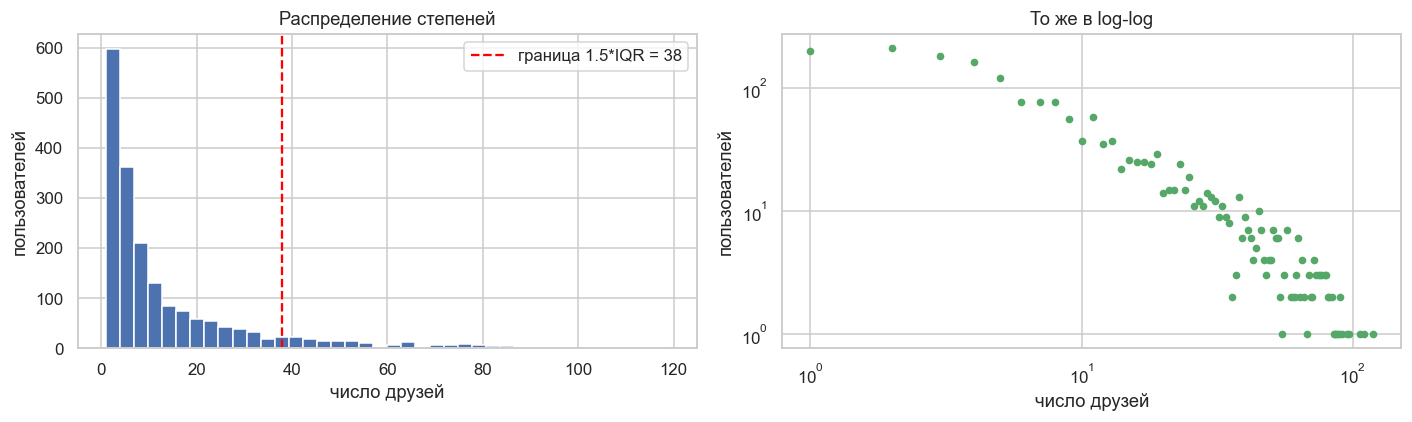

In [28]:
G = nx.from_pandas_edgelist(uf, "userID", "friendID")
deg = pd.Series(dict(G.degree()))
comps = sorted(nx.connected_components(G), key=len, reverse=True)
clust = nx.average_clustering(G)
print(f"компонент связности: {len(comps)}, крупнейшая: {len(comps[0])} узлов ({len(comps[0]) / n_users:.1%})")
print(f"средний коэффициент кластеризации: {clust:.3f} (случайный граф той же плотности: {density:.4f}, "
      f"отношение {clust / density:.0f})")
print(f"степень: мин {deg.min()}, медиана {deg.median():.0f}, среднее {deg.mean():.1f}, макс {deg.max()}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(deg, bins=40, color="#4C72B0")
ax[0].set_title("Распределение степеней"); ax[0].set_xlabel("число друзей"); ax[0].set_ylabel("пользователей")
ax[0].axvline(fence, color="red", ls="--", label=f"граница 1.5*IQR = {fence:.0f}"); ax[0].legend()
cnt = deg.value_counts().sort_index()
ax[1].loglog(cnt.index, cnt.values, "o", ms=4, color="#55A868")
ax[1].set_title("То же в log-log"); ax[1].set_xlabel("число друзей"); ax[1].set_ylabel("пользователей")
plt.tight_layout(); plt.show()

**Вывод.** Распределение степеней скошено вправо: медиана 6, среднее 13.4, максимум 119. Большинство пользователей имеют несколько друзей, небольшая доля - десятки; такая форма типична для социальных графов. Граф практически связный: крупнейшая компонента содержит 97.4% пользователей, остальные 19 компонент - небольшие изолированные группы.

Средний коэффициент кластеризации 0.187 в 26 раз выше, чем у случайного графа той же плотности. Следовательно, связи образуют выраженные треугольники - друзья пользователя часто дружат между собой, - и методы, использующие общих соседей (UserKNN, EASE), применимы к задаче.

### 2.4. Пользователи с наибольшей степенью

Эти пользователи образуют рекомендации MostPop (п. 4.1). Данные анонимизированы, поэтому распознаем по ID.

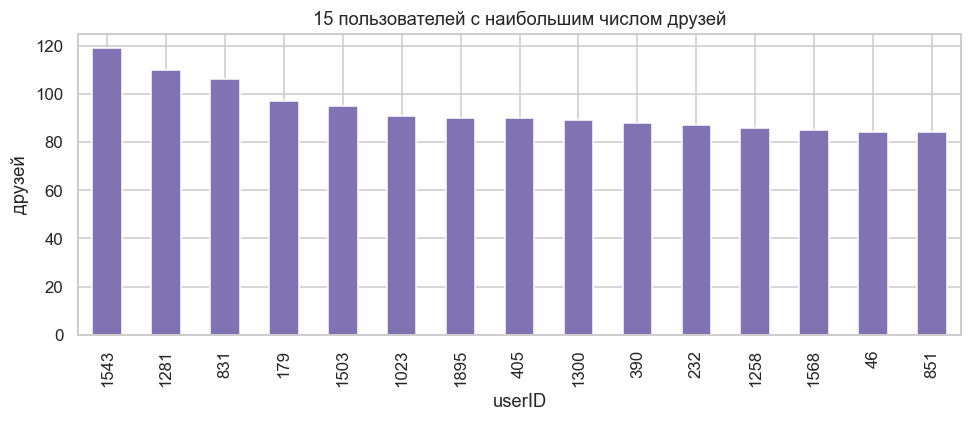

на 15 пользователей приходится 5.5% концов всех связей


In [29]:
top_deg = deg.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 4))
top_deg.plot(kind="bar", color="#8172B3", ax=ax)
ax.set_title("15 пользователей с наибольшим числом друзей"); ax.set_xlabel("userID"); ax.set_ylabel("друзей")
plt.tight_layout(); plt.show()
print(f"на 15 пользователей приходится {top_deg.sum() / len(uf):.1%} концов всех связей")

**Вывод.** На 15 пользователей с наибольшей степенью приходится 5.5% концов всех связей: популярность распределена неравномерно, но не сосредоточена в нескольких узлах. MostPop рекомендует всем пользователям одних и тех же кандидатов из этой группы, поэтому его покрытие заведомо мало.

### 2.5. Предобработка: выбор k-ядра

Пользователь с одним-двумя друзьями после разбиения на обучение и тест может остаться без друзей в обучающей выборке (холодный старт). Для него у персонализированных методов нет входных данных, и метрики измеряют не качество метода, а отсутствие данных. Поэтому ограничиваем граф k-ядром - максимальным подграфом, в котором у каждого узла не меньше k соседей внутри подграфа.

Порог k выбираем по компромиссу между долей сохранённых пользователей и связей и долей тестовых пользователей без друзей в обучении. Разбиение то же, что в п. 3: 80% рёбер - обучение, 20% - тест.

In [30]:
def make_core(k):
    """k-ядро графа: узлы с переиндексацией 0..n-1 и неориентированные рёбра (i < j)."""
    H = nx.k_core(G, k)
    nodes = sorted(H.nodes)
    ids = {u: i for i, u in enumerate(nodes)}
    edges = np.array(sorted((min(ids[a], ids[b]), max(ids[a], ids[b])) for a, b in H.edges))
    return nodes, edges


def split_edges(edges, frac, seed):
    m = np.random.default_rng(seed).random(len(edges)) < frac
    return edges[m], edges[~m]


rows = []
for k in [1, 2, 3, 5, 7, 10, 15]:
    nodes, ed = make_core(k)
    tr, te = split_edges(ed, 0.8, RND)
    deg_tr = np.bincount(tr.ravel(), minlength=len(nodes))
    te_users = np.unique(te.ravel())
    rows.append({"k": k, "пользователей": len(nodes), "доля пользователей": len(nodes) / n_users,
                 "дружб": len(ed), "доля дружб": len(ed) / n_edges, "медианная степень": np.median(np.bincount(ed.ravel())),
                 "тест-пользователей без друзей в обучении": (deg_tr[te_users] == 0).mean(),
                 "тест-пользователей с < 3 друзьями в обучении": (deg_tr[te_users] < 3).mean()})
core_table = pd.DataFrame(rows).set_index("k")
core_table.round(3)

,пользователей,доля пользователей,дружб,доля дружб,медианная степень,тест-пользователей без друзей в обучении,тест-пользователей с < 3 друзьями в обучении
k,,,,,,,
1,1892,1.000,12717,1.000,6.0,0.038,0.167
2,1669,0.882,12509,0.984,8.0,0.009,0.158
3,1432,0.757,12062,0.948,9.0,0.000,0.109
5,1025,0.542,10719,0.843,14.0,0.000,0.010
7,794,0.420,9523,0.749,17.0,0.000,0.000
10,495,0.262,7187,0.565,23.0,0.000,0.000
15,292,0.154,4828,0.380,29.0,0.000,0.000


**Вывод.** При k = 1 (весь граф) 3.8% тестовых пользователей не имеют ни одного друга в обучении, при k = 2 - 0.9%, начиная с k = 3 таких пользователей нет. Выбираем k = 3: это наименьший порог без холодного старта в тесте, он сохраняет 75.7% пользователей и 94.8% связей.

Более высокий порог уменьшает долю тестовых пользователей со слабым сигналом (меньше 3 друзей в обучении: 10.9% при k = 3 и 1% при k = 5), но при k = 5 исключается уже 46% пользователей. Влияние порога на результат сравнения методов проверяется в п. 6.2.

In [31]:
CORE_K = 3
nodes, edges = make_core(CORE_K)
U = len(nodes)
inv = dict(enumerate(nodes))
print(f"{CORE_K}-ядро: пользователей {U}, дружб {len(edges)}")

3-ядро: пользователей 1432, дружб 12062


## 3. Разбиение на обучение, валидацию и тест

Разбиваем рёбра (неориентированные дружбы), а не строки файла: обе записи `(u, v)` и `(v, u)` попадают в одну часть, поэтому скрытая связь не утекает в обучение. Схема:
- 80% рёбер - обучение, 20% - тест;
- из обучающих рёбер ещё 10% отделяются в валидацию, на ней подбираются гиперпараметры (п. 5.4). Тест используется только для итогового сравнения.

Матрица смежности `A` строится симметрично только по рёбрам обучения.

In [32]:
def adj(ed, n):
    r = np.r_[ed[:, 0], ed[:, 1]]; c = np.r_[ed[:, 1], ed[:, 0]]
    return sp.csr_matrix((np.ones(len(r)), (r, c)), shape=(n, n))


def holdout(ed):
    """Для каждого пользователя - множество скрытых друзей."""
    d = collections.defaultdict(set)
    for a, b in ed:
        d[a].add(b); d[b].add(a)
    return dict(d)


tr_e, te_e = split_edges(edges, 0.8, RND)              # обучение / тест
fit_e, va_e = split_edges(tr_e, 0.9, RND + 1)          # внутри обучения: обучение для подбора / валидация
A, test = adj(tr_e, U), holdout(te_e)
A_fit, val = adj(fit_e, U), holdout(va_e)

deg_tr = np.asarray(A.sum(axis=1)).ravel()
cold = [u for u in test if deg_tr[u] == 0]
print(f"обучение: {len(tr_e)} дружб (из них {len(fit_e)} для подбора, {len(va_e)} валидация), тест: {len(te_e)}")
print(f"пользователей в тесте: {len(test)}, из них без друзей в обучении: {len(cold)}")
print(f"скрытых друзей на тестового пользователя: медиана {np.median([len(s) for s in test.values()]):.0f}, "
      f"среднее {np.mean([len(s) for s in test.values()]):.1f}")

обучение: 9704 дружб (из них 8694 для подбора, 1010 валидация), тест: 2358
пользователей в тесте: 1177, из них без друзей в обучении: 0
скрытых друзей на тестового пользователя: медиана 2, среднее 4.0


**Вывод.** В тесте 1177 пользователей, у каждого есть хотя бы один друг в обучении. Число скрытых друзей распределено неравномерно: медиана 2, среднее 4.0. Для пользователя с двумя скрытыми друзьями Precision@10 не может превысить 0.2, поэтому абсолютные значения Precision малы при любом методе; методы сравниваются между собой и с бейзлайном MostPop.

## 4. Методы формирования рекомендаций

Каждый метод по матрице смежности `A` возвращает матрицу оценок `S` размера `n x n`: `S[u, v]` - оценка пригодности пользователя `v` в друзья пользователю `u`. Рекомендации - K кандидатов с наибольшей оценкой, кроме самого `u` и его друзей в обучении. Методы взяты из четырёх семейств: популярность, соседские, линейные, матричные разложения.

### 4.1. MostPop

`S[u, v] = deg(v)` - степень кандидата в обучающем графе. Метод неперсонализированный: всем рекомендуются одни и те же пользователи с наибольшим числом друзей. Служит нижней границей качества.

In [33]:
def mostpop(A):
    pop = np.asarray(A.sum(axis=1)).ravel()
    return np.tile(pop, (A.shape[0], 1)).astype(np.float32)

### 4.2. UserKNN

Сходство пользователей - косинус строк матрицы смежности:

`sim(u, w) = |N(u) ∩ N(w)| / sqrt(|N(u)|*|N(w)|)`,

где `N(u)` - множество друзей `u`. Числитель - число общих друзей, знаменатель нормирует его на размеры окружений. Оценка кандидата - сумма сходств с теми из `n_neighbors` ближайших соседей `u`, кто дружит с `v`:

`S[u, v] = Σ_{w ∈ kNN(u)} sim(u, w)*A[w, v]`.

Кандидат `v` получает высокую оценку, если с ним дружат пользователи с похожим на `u` кругом общения. Гиперпараметр - `n_neighbors`.

In [34]:
def userknn(A, n_neighbors=50):
    An = normalize(A, norm="l2", axis=1)
    sim = (An @ An.T).toarray()
    np.fill_diagonal(sim, 0.0)
    if n_neighbors < sim.shape[0] - 1:                          # оставляем n_neighbors наибольших сходств в строке
        kth = -np.partition(-sim, n_neighbors - 1, axis=1)[:, [n_neighbors - 1]]
        sim[sim < kth] = 0.0
    return (sim @ A.toarray()).astype(np.float32)

### 4.3. EASE

Линейная модель `S = A*W` (Steck, 2019). Матрица весов `W` размера `n x n` с нулевой диагональю минимизирует `||A - A*W||² + λ||W||²`. Решение в замкнутой форме:

`P = (AᵀA + λI)⁻¹`, `W[i, j] = -P[i, j] / P[j, j]`, `W[j, j] = 0`.

Для симметричного графа `AᵀA` - матрица чисел общих друзей, поэтому EASE можно рассматривать как оценку по общим друзьям, в которой веса связей подобраны регрессией. Нулевая диагональ запрещает тривиальное решение `W = I`. Гиперпараметр - коэффициент регуляризации `λ`.

In [35]:
def ease(A, lam=100.0):
    gram = (A.T @ A).toarray()
    gram[np.diag_indices_from(gram)] += lam
    P = np.linalg.inv(gram)
    W = -P / np.diag(P)
    np.fill_diagonal(W, 0.0)
    return np.asarray(A @ W, dtype=np.float32)

### 4.4. PureSVD

Усечённое сингулярное разложение матрицы смежности `A ~ U_k Σ_k V_kᵀ`, оценки `S = U_k Σ_k V_kᵀ`. Каждый пользователь представляется вектором в k-мерном пространстве, и связь предсказывается между пользователями с близким положением в графе (похожими окружениями), даже без общих друзей. Гиперпараметр - число компонент `k`.

In [36]:
def puresvd(A, k=48):
    u, s, vt = svds(A.astype(np.float64), k=k, random_state=RND)
    return ((u * s) @ vt).astype(np.float32)

## 5. Метрики качества

### 5.1. Что считается релевантным

- Релевантные объекты для пользователя `u` - его друзья, скрытые в тестовой выборке: множество `Rel(u)`, `n_rel(u)` - его размер.
- Кандидаты - все пользователи ядра, кроме самого `u` и его друзей в обучении.
- Релевантность бинарная: кандидат либо входит в `Rel(u)`, либо нет.
- Метрики считаются по списку из K = 10 рекомендаций и усредняются по пользователям, у которых `Rel(u)` непусто.

### 5.2. Определения

`R_K(u)` - список из K рекомендаций, `hit_i = 1`, если i-й элемент списка входит в `Rel(u)`, иначе 0.

| Метрика | Формула | Что измеряет |
|---|---|---|
| Precision@K | `Σ hit_i / K` | доля верных рекомендаций в списке |
| Recall@K | `Σ hit_i / n_rel(u)` | доля скрытых друзей, найденных в списке |
| MAP@K | `Σ_i hit_i*Precision@i / min(n_rel(u), K)` | точность с учётом позиций попаданий |
| NDCG@K | `DCG / IDCG`, `DCG = Σ_i hit_i / log2(i + 1)` | попадание на первых позициях весит больше |
| Novelty | среднее `-log2 p(v)`, `p(v) = (deg(v) + 1) / n` | насколько непопулярны рекомендованные пользователи |
| Diversity | среднее по парам списка `1 - cos(A_v, A_w)` | насколько различаются круги друзей рекомендованных |
| Coverage | доля пользователей, рекомендованных хотя бы одному тестовому пользователю | охват каталога |

IDCG - DCG идеального списка, в котором все `min(n_rel(u), K)` релевантных стоят первыми. MAP@K и NDCG@K - метрики ранжирования; Novelty и Diversity - специфические для рекомендательных систем.

In [37]:
def recommend(score, A, K=K):
    S = score.copy()
    S[A.nonzero()] = -np.inf                         # друзья в обучении
    np.fill_diagonal(S, -np.inf)                     # сам пользователь
    idx = np.argpartition(-S, K, axis=1)[:, :K]
    rows = np.arange(S.shape[0])[:, None]
    return idx[rows, np.argsort(-S[rows, idx], axis=1)]


def user_metrics(r, rel, K=K):
    hit = np.isin(r, list(rel)).astype(float)
    m = min(len(rel), K)
    prec_i = np.cumsum(hit) / np.arange(1, K + 1)
    dcg = (hit / np.log2(np.arange(2, K + 2))).sum()
    idcg = (1 / np.log2(np.arange(2, m + 2))).sum()
    return {"Precision": hit.sum() / K, "Recall": hit.sum() / len(rel),
            "MAP": (hit * prec_i).sum() / m, "NDCG": dcg / idcg}


def evaluate(score, A, held, K=K):
    rec = recommend(score, A, K)
    pop = np.asarray(A.sum(axis=1)).ravel()
    p = (pop + 1) / A.shape[0]
    prof = normalize(A, norm="l2", axis=1)
    iu = np.triu_indices(K, k=1)
    rows, seen = [], set()
    for u, rel in held.items():
        r = rec[u]
        V = prof[r].toarray()
        row = user_metrics(r, rel, K)
        row["Novelty"] = -np.log2(p[r]).mean()
        row["Diversity"] = 1 - (V @ V.T)[iu].mean()
        rows.append(row)
        seen.update(r.tolist())
    out = pd.DataFrame(rows).mean()
    out["Coverage"] = len(seen) / A.shape[0]
    return out.rename(lambda c: f"{c}@{K}" if c in ("Precision", "Recall", "MAP", "NDCG") else c)

### 5.3. Пример расчёта

Пользователь из теста, его 10 рекомендаций EASE (с `λ = 100`), отметка попадания и метрики для этого пользователя.

In [38]:
rec_ex = recommend(ease(A), A)
u0 = next((u for u, rel in test.items() if 3 <= len(rel) <= 6 and 1 <= np.isin(rec_ex[u], list(rel)).sum() < len(rel)),
          next(iter(test)))
r0 = rec_ex[u0]
common = np.asarray((A[u0] @ A.T).todense()).ravel()
print(f"userID {inv[u0]}: друзей в обучении {int(deg_tr[u0])}, скрытых в тесте n_rel = {len(test[u0])}")
display(pd.DataFrame({"позиция": range(1, K + 1), "рекомендован userID": [inv[v] for v in r0],
                      "общих друзей": common[r0].astype(int),
                      "hit": np.isin(r0, list(test[u0])).astype(int)}).set_index("позиция").T)
m0 = user_metrics(r0, test[u0])
pos = np.where(np.isin(r0, list(test[u0])))[0] + 1
print(f"попадания на позициях {list(pos)}")
print(f"Precision@10 = {len(pos)}/10 = {m0['Precision']:.2f};  Recall@10 = {len(pos)}/{len(test[u0])} = {m0['Recall']:.3f}")
print(f"MAP@10 = ({' + '.join(f'{j + 1}/{p}' for j, p in enumerate(pos))}) / {min(len(test[u0]), K)} = {m0['MAP']:.3f};  "
      f"NDCG@10 = {m0['NDCG']:.3f}")

userID 7: друзей в обучении 15, скрытых в тесте n_rel = 3


позиция,1,2,3,4,5,6,7,8,9,10
рекомендован userID,405,545,110,236,1027,1283,1895,1773,831,310
общих друзей,9,5,2,3,8,4,4,3,2,5
hit,0,1,0,0,0,0,0,0,0,0


попадания на позициях [np.int64(2)]
Precision@10 = 1/10 = 0.10;  Recall@10 = 1/3 = 0.333
MAP@10 = (1/2) / 3 = 0.167;  NDCG@10 = 0.296


**Пояснение к расчёту.** Единственное попадание - на 2-й позиции. MAP@10 = точность на позиции попадания (1/2), делённая на `min(n_rel, K) = 3`. NDCG@10 = DCG / IDCG: `DCG = 1/log2(3) = 0.631`, `IDCG = 1 + 1/log2(3) + 1/log2(4) = 2.131` (три релевантных на первых трёх позициях), отношение 0.296. Кандидаты упорядочены не строго по числу общих друзей: EASE учитывает не только их количество, но и веса связей, подобранные регрессией.

### 5.4. Подбор гиперпараметров на валидации

Модели обучаются на `A_fit` (обучение без валидационных рёбер), качество измеряется по NDCG@10 на валидационных рёбрах. Перебираемые значения:
- UserKNN: `n_neighbors` ∈ {5, 10, 20, 50, 100, 200, 500, все};
- EASE: `λ` ∈ {1, 10, 30, 100, 300, 1000, 3000};
- PureSVD: `k` ∈ {4, 8, 16, 32, 64, 128, 256}.

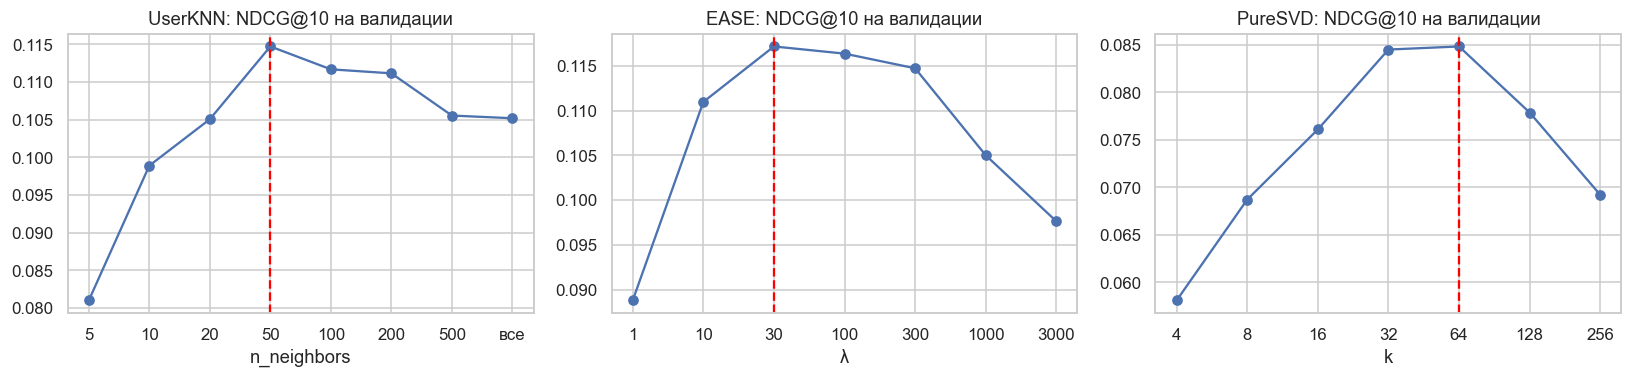

UserKNN (n_neighbors): {5: 0.081, 10: 0.0989, 20: 0.105, 50: 0.1147, 100: 0.1117, 200: 0.1111, 500: 0.1055, 'все': 0.1052}
EASE (λ): {1: 0.0888, 10: 0.111, 30: 0.1172, 100: 0.1164, 300: 0.1147, 1000: 0.105, 3000: 0.0976}
PureSVD (k): {4: 0.0581, 8: 0.0687, 16: 0.0761, 32: 0.0845, 64: 0.0848, 128: 0.0779, 256: 0.0692}
выбранные значения: {'UserKNN': 50, 'EASE': 30, 'PureSVD': 64}


In [39]:
GRID = {"UserKNN": (userknn, "n_neighbors", [5, 10, 20, 50, 100, 200, 500, U - 1]),
        "EASE": (ease, "λ", [1, 10, 30, 100, 300, 1000, 3000]),
        "PureSVD": (puresvd, "k", [4, 8, 16, 32, 64, 128, 256])}
tuning, BEST = {}, {}
for name, (fn, pname, values) in GRID.items():
    tuning[name] = pd.Series({v: evaluate(fn(A_fit, v), A_fit, val)["NDCG@10"] for v in values}, name=pname)
    BEST[name] = tuning[name].idxmax()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, (name, s) in zip(ax, tuning.items()):
    a.plot(range(len(s)), s.values, "o-")
    a.set_xticks(range(len(s))); a.set_xticklabels(["все" if v == U - 1 else v for v in s.index])
    a.set_title(f"{name}: NDCG@10 на валидации"); a.set_xlabel(s.name)
    a.axvline(list(s.index).index(BEST[name]), color="red", ls="--")
plt.tight_layout(); plt.show()
for name, s in tuning.items():
    print(f"{name} ({s.name}):", {("все" if v == U - 1 else int(v)): round(x, 4) for v, x in s.items()})
print("выбранные значения:", {k: ("все" if v == U - 1 else int(v)) for k, v in BEST.items()})

**Вывод.** У всех трёх методов максимум NDCG@10 находится внутри перебираемого диапазона, то есть диапазон выбран достаточно широким.
- UserKNN: максимум при 50 соседях (0.115). При 5-10 соседях ненулевую оценку получают немногие кандидаты, при использовании всех пользователей оценка зашумляется слабо похожими соседями.
- EASE: максимум при λ = 30 (0.117). При малых λ модель переобучается на обучающие связи, при больших веса стягиваются к нулю.
- PureSVD: максимум при k = 64 (0.085). Малое число компонент не передаёт локальную структуру графа, большое начинает воспроизводить шум.

Около максимума зависимости пологие (UserKNN при 50-200 соседях и EASE при λ от 30 до 300 отличаются не более чем на 0.004), поэтому выбор значений устойчив. Абсолютные значения на валидации и на тесте не сопоставляются: объём скрытых связей в них разный.

## 6. Сравнение методов на тесте

Модели с выбранными гиперпараметрами обучаются на полной обучающей выборке `A` (обучение + валидация) и оцениваются на тесте.

In [40]:
METHODS = {"MostPop": lambda A: mostpop(A),
           "UserKNN": lambda A: userknn(A, BEST["UserKNN"]),
           "EASE": lambda A: ease(A, BEST["EASE"]),
           "PureSVD": lambda A: puresvd(A, BEST["PureSVD"])}
results = pd.DataFrame({name: evaluate(fn(A), A, test) for name, fn in METHODS.items()}).T
results.round(4)

,Precision@10,Recall@10,MAP@10,NDCG@10,Novelty,Diversity,Coverage
MostPop,0.0173,0.0456,0.0198,0.0354,4.1898,0.8692,0.0154
UserKNN,0.0698,0.2066,0.1060,0.1634,5.2990,0.8506,0.5279
EASE,0.0664,0.1983,0.1002,0.1557,5.4745,0.8783,0.6592
PureSVD,0.0519,0.1466,0.0731,0.1172,5.2977,0.8717,0.3687


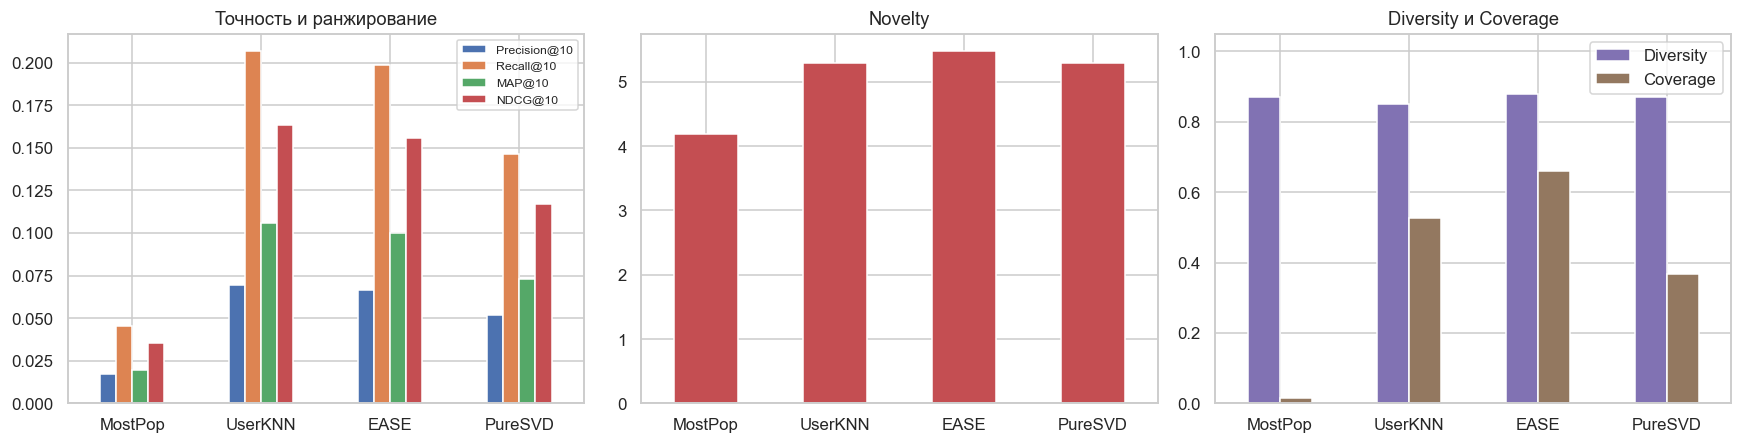

In [41]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
results[["Precision@10", "Recall@10", "MAP@10", "NDCG@10"]].plot(kind="bar", ax=ax[0])
ax[0].set_title("Точность и ранжирование"); ax[0].legend(fontsize=8)
results[["Novelty"]].plot(kind="bar", ax=ax[1], color="#C44E52", legend=False); ax[1].set_title("Novelty")
results[["Diversity", "Coverage"]].plot(kind="bar", ax=ax[2], color=["#8172B3", "#937860"])
ax[2].set_title("Diversity и Coverage"); ax[2].set_ylim(0, 1.05)
for a in ax:
    a.tick_params(axis="x", rotation=0); a.set_xlabel("")
plt.tight_layout(); plt.show()

**Вывод.**
- Точность и ранжирование: UserKNN (NDCG@10 = 0.163) и EASE (0.156) близки и в 4.4-4.6 раза превосходят MostPop (0.035); PureSVD (0.117) занимает промежуточное положение. Все метрики точности (Precision, Recall, MAP, NDCG) дают один и тот же порядок методов.
- Новизна и покрытие: EASE рекомендует менее популярных пользователей (Novelty 5.47 против 5.30 у UserKNN) и охватывает больше пользователей (Coverage 0.66 против 0.53). Вероятная причина - нормировка весов `W` на диагональ обратной матрицы, которая понижает вклад кандидатов с большой степенью. MostPop рекомендует 1.5% пользователей: всем выдаётся один и тот же список.
- Diversity у всех методов 0.85-0.88: круги друзей рекомендованных пользователей пересекаются слабо, и по этой метрике методы практически не различаются.

Итог для одного разбиения: по точности лидирует UserKNN, по новизне и покрытию - EASE. Значима ли разница между ними, проверяется в п. 6.1.

### 6.1. Устойчивость к разбиению

Результат одного случайного разбиения может зависеть от того, какие рёбра попали в тест. Повторяем разбиение train/test с пятью разными seed (гиперпараметры фиксированы) и приводим среднее и стандартное отклонение.

In [42]:
runs = []
for seed in range(5):
    tr_s, te_s = split_edges(edges, 0.8, 100 + seed)
    A_s, test_s = adj(tr_s, U), holdout(te_s)
    for name, fn in METHODS.items():
        runs.append({"seed": seed, "метод": name, **evaluate(fn(A_s), A_s, test_s)})
runs = pd.DataFrame(runs)
cols = ["Precision@10", "Recall@10", "NDCG@10", "Novelty", "Coverage"]
agg = runs.groupby("метод")[cols].agg(["mean", "std"])
display(pd.DataFrame({c: agg[(c, "mean")].map("{:.4f}".format) + " ± " + agg[(c, "std")].map("{:.4f}".format)
                      for c in cols}).loc[list(METHODS)])
wide = runs.pivot(index="seed", columns="метод", values="NDCG@10")
print("NDCG@10 по разбиениям:"); display(wide[list(METHODS)].round(4))

,Precision@10,Recall@10,NDCG@10,Novelty,Coverage
метод,,,,,
MostPop,0.0187 ± 0.0012,0.0433 ± 0.0041,0.0341 ± 0.0035,4.2260 ± 0.0280,0.0149 ± 0.0008
UserKNN,0.0693 ± 0.0025,0.1968 ± 0.0104,0.1572 ± 0.0086,5.3072 ± 0.0236,0.5214 ± 0.0065
EASE,0.0667 ± 0.0023,0.1879 ± 0.0115,0.1508 ± 0.0060,5.4783 ± 0.0213,0.6499 ± 0.0163
PureSVD,0.0487 ± 0.0023,0.1310 ± 0.0071,0.1069 ± 0.0044,5.3191 ± 0.0133,0.3719 ± 0.0045


NDCG@10 по разбиениям:


метод,MostPop,UserKNN,EASE,PureSVD
seed,,,,
0,0.0369,0.1515,0.1512,0.1068
1,0.0336,0.1599,0.1514,0.1097
2,0.0324,0.1468,0.1415,0.0996
3,0.0383,0.1694,0.1582,0.1107
4,0.0295,0.1583,0.1515,0.1074


**Вывод.** Стандартное отклонение NDCG@10 по разбиениям - 0.004-0.009. Средняя разница UserKNN и EASE (0.157 против 0.151) сопоставима с этим разбросом, однако в парном сравнении на одних и тех же разбиениях UserKNN выше EASE во всех пяти случаях (на 0.0003-0.011). Следовательно, преимущество UserKNN по точности систематическое, но небольшое (~4%).

Порядок UserKNN > EASE > PureSVD > MostPop по точности и превосходство EASE по Novelty и Coverage (0.650 ± 0.016 против 0.521 ± 0.007) сохраняются на всех разбиениях.

### 6.2. Чувствительность к порогу k-ядра

Проверяем, сохраняется ли порядок методов при другом пороге предобработки (п. 2.5): k = 2, 5, 10 против выбранного k = 3. Гиперпараметры те же.

In [43]:
rows = []
for k in [2, 3, 5, 10]:
    nodes_k, ed_k = make_core(k)
    tr_k, te_k = split_edges(ed_k, 0.8, RND)
    A_k, test_k = adj(tr_k, len(nodes_k)), holdout(te_k)
    for name, fn in METHODS.items():
        rows.append({"k": k, "метод": name, "NDCG@10": evaluate(fn(A_k), A_k, test_k)["NDCG@10"]})
pd.DataFrame(rows).pivot(index="метод", columns="k", values="NDCG@10").loc[list(METHODS)].round(4)

k,2,3,5,10
метод,,,,
MostPop,0.0310,0.0354,0.0290,0.0450
UserKNN,0.1441,0.1634,0.1483,0.1659
EASE,0.1367,0.1557,0.1434,0.1551
PureSVD,0.1061,0.1172,0.1168,0.1282


**Вывод.** При всех порогах k порядок методов одинаков: UserKNN > EASE > PureSVD > MostPop. Абсолютные значения меняются: при k = 10 в ядре остаются только активные пользователи (медиана 23 друга), и метрики выше. Выбор порога k = 3 не влияет на выводы сравнения.

### 6.3. Пример рекомендаций

Пользователь с наибольшим числом скрытых друзей; 5 первых рекомендаций каждого персонализированного метода, число общих друзей с кандидатом в обучении и попадание в тест.

In [44]:
u1 = max(test, key=lambda u: len(test[u]))
common = np.asarray((A[u1] @ A.T).todense()).ravel()
print(f"userID {inv[u1]}: друзей в обучении {int(deg_tr[u1])}, скрытых в тесте {len(test[u1])}")
tabs = {}
for name in ["UserKNN", "EASE", "PureSVD"]:
    r = recommend(METHODS[name](A), A, 5)[u1]
    tabs[name] = [f"{inv[v]} ({int(common[v])}){' +' if v in test[u1] else ''}" for v in r]
pd.DataFrame(tabs, index=range(1, 6)).rename_axis("позиция")

userID 1281: друзей в обучении 79, скрытых в тесте 26


,UserKNN,EASE,PureSVD
позиция,,,
1,1488 (10) +,1543 (9) +,752 (2)
2,1543 (9) +,1488 (10) +,1662 (7)
3,731 (3),1213 (10),202 (2)
4,1879 (7),1671 (4),731 (3)
5,752 (2),752 (2),183 (1)


Формат ячейки: `userID (число общих друзей)`, `+` - кандидат является скрытым другом.

**Вывод.** UserKNN и EASE ставят на первые позиции одних и тех же кандидатов с наибольшим числом общих друзей (1488 и 1543, по 9-10 общих друзей), и оба кандидата являются скрытыми друзьями. PureSVD выдаёт кандидатов с 1-7 общими друзьями и в первых пяти не попадает ни разу: латентные компоненты описывают крупномасштабную структуру графа, а для предсказания дружбы решающим оказывается локальный сигнал - общие друзья.

## 7. Предложения по улучшению и выводы

### 7.1. Предложения по улучшению

1. **Индексы предсказания связей.** Adamic-Adar и Resource Allocation учитывают общих друзей с весом, обратным их степени: общий друг с 5 друзьями информативнее общего друга-хаба со 100. Их можно использовать как отдельные методы или как признаки.
2. **Комбинация UserKNN и EASE.** Методы близки по точности и различаются по покрытию и новизне; взвешенная сумма нормированных оценок позволяет управлять этим компромиссом.
3. **Контентный сигнал.** Прослушивания (`user_artists.dat`) и теги дают сходство вкусов пользователей. Это дополнительный признак для пользователей с малым числом друзей, которые сейчас исключены k-ядром.
4. **Графовые эмбеддинги** (node2vec, LightGCN) вместо PureSVD: учитывают локальную структуру окрестности, которую линейное разложение не передаёт.
5. **Обучение ранжированию.** Оценки методов, число общих друзей и степени пользователей как признаки для модели ранжирования (градиентный бустинг с ранжирующей функцией потерь).
6. **Временное разбиение.** Дат образования дружбы в датасете нет, поэтому разбиение случайное. При их наличии тест следует строить из более поздних связей - это ближе к реальной задаче.

### 7.2. Выводы

1. Использован социальный граф Last.fm (HetRec-2011): 1892 пользователя, 12717 дружб, плотность 0.71%. Данные не содержат пропусков, дубликатов и петель; 9.1% пользователей - выбросы по степени, они оставлены как реальные узлы графа. Коэффициент кластеризации в 26 раз выше, чем у случайного графа той же плотности, что обосновывает использование общих соседей.
2. Предобработка - 3-ядро графа (1432 пользователя, 12062 дружбы): наименьший порог, при котором у всех тестовых пользователей есть друзья в обучении.
3. Рёбра разбиты на обучение (80%) и тест (20%); гиперпараметры подобраны на отдельной валидации: UserKNN - 50 соседей, EASE - λ = 30, PureSVD - 64 компоненты.
4. Сравнение на тесте (среднее по 5 разбиениям): UserKNN - NDCG@10 = 0.157 ± 0.009, EASE - 0.151 ± 0.006, PureSVD - 0.107 ± 0.004, MostPop - 0.034 ± 0.004. UserKNN лучше EASE на всех разбиениях, но разница мала (~4%).
5. EASE даёт более широкую и новую выдачу (Coverage 0.65 против 0.52, Novelty 5.48 против 5.31). Выбор между UserKNN и EASE - компромисс между точностью и охватом.
6. PureSVD уступает соседским и линейным методам: для предсказания дружбы локальный сигнал общих друзей важнее глобальной структуры графа. MostPop служит нижней границей качества.